In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import make_moons, make_circles
from sklearn.metrics import accuracy_score

from nanosurrogate.models import DifferentiableNanoNode

%matplotlib inline

I0000 00:00:1794655338.069074  236254 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794655338.116924  236254 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794655339.313070  236254 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
def optimize_2d_pattern_gates(
    node: DifferentiableNanoNode,
    X_data: np.ndarray,
    y_data: np.ndarray,
    ctrl_indices: list[int] = [1, 2, 4],
    data_indices: list[int] = [0, 3, 5, 6],
    v_max: float = 0.03,
    steps: int = 800,
    lr: float = 0.02,
    seed: int = 42,
):
    """
    Optimizes the static control gate voltages and input encoding weights of a 
    single nanoparticle network to classify non-linear 2D patterns (Moons / Circles).

    Physical Setup
    --------------
    The 7 electrodes of the single nanoparticle network are partitioned into:
    - `ctrl_indices` (default: E1, E2, E4): Static DC tuning gates programmed to fixed 
      voltages across all samples to configure the internal potential landscape.
    - `data_indices` (default: E0, E3, E5, E6): Dynamic data input electrodes receiving 
      an affine projection of the 2D input coordinates $(x_1, x_2)$.
    All electrode potentials are strictly bounded within `[-v_max, +v_max]` Volts 
    via a hyperbolic tangent (`tanh`) saturation function to respect experimental limits.

    Parameters
    ----------
    node : DifferentiableNanoNode
        Pre-trained, frozen differentiable surrogate model of the nanoparticle network.
    X_data : np.ndarray
        Normalized 2D input coordinates of shape `(n_samples, 2)`.
    y_data : np.ndarray
        Binary class labels (`0` or `1`) of shape `(n_samples,)`.
    ctrl_indices : list of int
        Indices of the electrodes acting as static DC control gates.
    data_indices : list of int
        Indices of the electrodes receiving the 2D input signals.
    v_max : float, default=0.03
        Maximum allowable voltage magnitude per electrode in Volts (0.03 V = 30 mV).
    steps : int, default=800
        Number of Adam gradient descent iterations.
    lr : float, default=0.02
        Learning rate for the voltage optimizer.
    seed : int, default=42
        Random seed for reproducible voltage initialization.

    Returns
    -------
    forward_pass : callable
        Function mapping a 2D input tensor `(N, 2)` to the physical output current `[pA]`.
    i_thresh : float
        Learned decision threshold current $I_{\\mathrm{th}}$ in picoamperes [pA].
    i_gain : float
        Learned scaling gain (its sign determines whether Class 1 lies above or below $I_{\\mathrm{th}}$).
    ctrl_voltages_mV : np.ndarray
        Final optimized static DC control gate voltages in millivolts [mV].
    """
    tf.keras.utils.set_random_seed(seed)
    X_tf = tf.constant(X_data, dtype=tf.float32)
    y_tf = tf.constant(y_data.reshape(-1, 1), dtype=tf.float32)

    n_ctrl = len(ctrl_indices)
    n_data = len(data_indices)

    # Restore original electrode ordering [E0, E1, ..., E6] after concatenating ctrl & data tensors
    perm_order = np.argsort(ctrl_indices + data_indices)

    # Trainable experimental parameters (unconstrained latent variables passed through tanh)
    ctrl_latent = tf.Variable(tf.random.normal([1, n_ctrl], stddev=0.5), name="ctrl_gates")
    w_in        = tf.Variable(tf.random.normal([2, n_data], stddev=0.8), name="input_weights")
    b_in        = tf.Variable(tf.zeros([1, n_data]), name="input_bias")

    # Readout comparator parameters: Decision boundary is defined by I_out == i_thresh
    i_thresh = tf.Variable(0.0, dtype=tf.float32, name="current_threshold_pA")
    i_gain   = tf.Variable(1.0, dtype=tf.float32, name="readout_gain")

    trainable_vars = [ctrl_latent, w_in, b_in, i_thresh, i_gain]
    optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    bce_loss  = tf.keras.losses.BinaryCrossentropy(from_logits=True)

    def forward_pass(X_batch: tf.Tensor) -> tf.Tensor:
        """Maps 2D coordinates (N, 2) -> 7 Electrode Voltages [-30mV, +30mV] -> Current [pA]."""
        batch_size = tf.shape(X_batch)[0]

        # 1. Static control voltages (tiled identically across all samples in the batch)
        v_ctrl = v_max * tf.math.tanh(tf.tile(ctrl_latent, [batch_size, 1]))

        # 2. Dynamic data voltages encoding the 2D coordinates (x1, x2)
        v_data = v_max * tf.math.tanh(tf.matmul(X_batch, w_in) + b_in)

        # 3. Assemble full 7-electrode voltage vector in correct hardware order [E0..E6]
        V_combined = tf.concat([v_ctrl, v_data], axis=1)
        V_ordered  = tf.gather(V_combined, indices=perm_order, axis=1)

        return node(V_ordered)

    # Gradient descent loop over the hardware control parameters
    for _ in range(steps):
        with tf.GradientTape() as tape:
            I_out  = forward_pass(X_tf)
            logits = i_gain * (I_out - i_thresh)
            loss   = bce_loss(y_tf, logits)

        grads = tape.gradient(loss, trainable_vars)
        optimizer.apply_gradients(zip(grads, trainable_vars))

    ctrl_voltages_mV = (v_max * tf.math.tanh(ctrl_latent).numpy().flatten()) * 1e3
    return forward_pass, float(i_thresh.numpy()), float(i_gain.numpy()), ctrl_voltages_mV


### Execution: Run Optimization & Store Results

In [3]:
node = DifferentiableNanoNode("../models/hurdle_baseline")

datasets = {
    "Two Moons": make_moons(n_samples=400, noise=0.12, random_state=42),
    "Concentric Circles": make_circles(n_samples=400, noise=0.08, factor=0.5, random_state=42),
}

ctrl_idx = [1, 2, 4]
data_idx = [0, 3, 5, 6]

# Dictionary to store all results for subsequent visualization
experiment_results = {}

for name, (X_raw, y) in datasets.items():
    # Standardize 2D coordinates to zero mean and unit variance
    X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)

    print(f"\n--- Optimizing Single-Node Voltages for: {name} ---")
    forward_fn, thresh, gain, ctrl_mV = optimize_2d_pattern_gates(
        node, X, y, ctrl_indices=ctrl_idx, data_indices=data_idx
    )

    # Evaluate classification predictions and accuracy
    I_pred = forward_fn(tf.constant(X, dtype=tf.float32)).numpy().flatten()
    y_pred = ((gain * (I_pred - thresh)) >= 0.0).astype(int)
    acc = accuracy_score(y, y_pred) * 100

    print(f"Control Gate Voltages {['E' + str(i) for i in ctrl_idx]} [mV]: {np.round(ctrl_mV, 2)}")
    print(f"Readout Threshold Current I_th: {thresh:.2f} pA | Accuracy: {acc:.1f}%")

    experiment_results[name] = {
        "X": X,
        "y": y,
        "forward_fn": forward_fn,
        "thresh": thresh,
        "gain": gain,
        "ctrl_mV": ctrl_mV,
        "acc": acc,
    }

I0000 00:00:1794655340.645386  236254 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5590 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.6



--- Optimizing Single-Node Voltages for: Two Moons ---
Control Gate Voltages ['E1', 'E2', 'E4'] [mV]: [-3.43 -6.19 -2.08]
Readout Threshold Current I_th: -3.28 pA | Accuracy: 100.0%

--- Optimizing Single-Node Voltages for: Concentric Circles ---
Control Gate Voltages ['E1', 'E2', 'E4'] [mV]: [ 10.22 -19.    -9.42]
Readout Threshold Current I_th: -2.13 pA | Accuracy: 100.0%


### Visualization: Plot Physical Current Landscape & Decision Boundaries

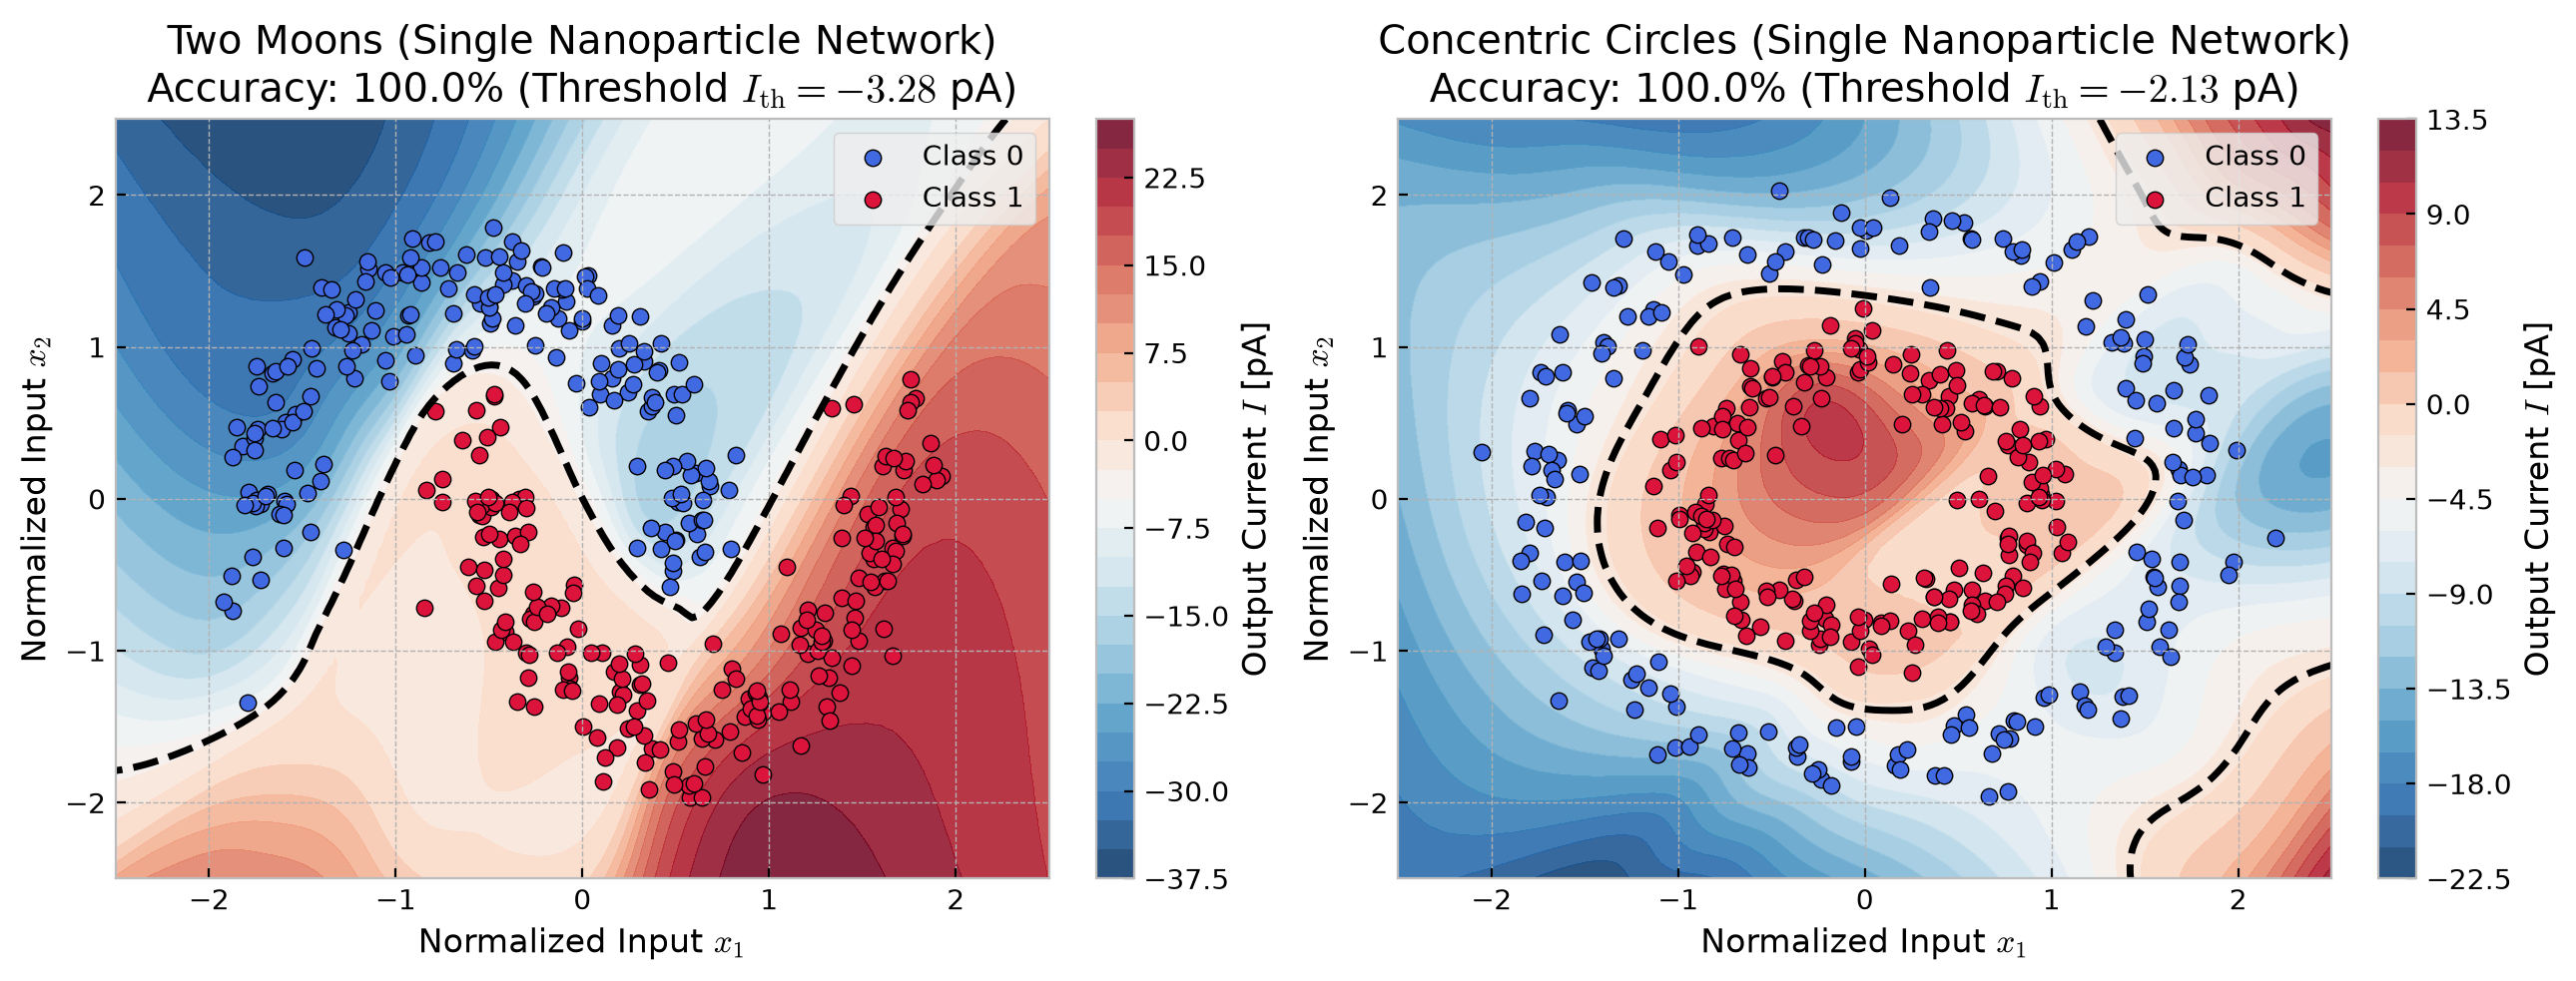

In [ ]:
with plt.style.context("bmh"):

    fig, axes = plt.subplots(1, 2, layout='constrained', dpi=200)
    fig.set_figwidth(fig.get_figwidth()*2)

    # Define 2D evaluation grid across the normalized input space
    grid_res = 150
    xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, grid_res), np.linspace(-2.5, 2.5, grid_res))
    grid_points = np.c_[xx.ravel(), yy.ravel()].astype(np.float32)
    grid_tf = tf.constant(grid_points)

    for ax, (name, res) in zip(axes, experiment_results.items()):
        X          = res["X"]
        y          = res["y"]
        forward_fn = res["forward_fn"]
        thresh     = res["thresh"]
        acc        = res["acc"]

        # Sample the continuous 2D physical current response across the meshgrid
        I_grid = forward_fn(grid_tf).numpy().reshape(xx.shape)

        # Plot physical current contours and learned threshold isoline (I_out == I_th)
        cf = ax.contourf(xx, yy, I_grid, levels=30, cmap="RdBu_r", alpha=0.85)
        ax.contour(xx, yy, I_grid, levels=[thresh], colors="black", linewidths=2.5, linestyles="--")

        # Overlay true data samples
        ax.scatter(X[y == 0, 0], X[y == 0, 1], c="royalblue", edgecolors="k", s=35, label="Class 0")
        ax.scatter(X[y == 1, 0], X[y == 1, 1], c="crimson", edgecolors="k", s=35, label="Class 1")

        ax.set_title(
            f"{name} (Single Nanoparticle Network)\n"
            f"Accuracy: {acc:.1f}% (Threshold $I_{{\\mathrm{{th}}}} = {thresh:.2f}$ pA)"
        )
        ax.set_xlabel("Normalized Input $x_1$")
        ax.set_ylabel("Normalized Input $x_2$")
        ax.legend(loc="upper right")
        plt.colorbar(cf, ax=ax, label="Output Current $I$ [pA]")

    fig.savefig("../plots/2d_patterns.png", bbox_inches='tight')